# Baseline [17] — Reis & Ribeiro (2024): DCNN face-recognition similarity scores
**Reference:** P. M. G. I. Reis & R. O. Ribeiro, "A forensic evaluation method for DeepFake detection using DCNN-based facial similarity scores," *Forensic Science International*, 358, 111747, 2024. doi:10.1016/j.forsciint.2023.111747

**Method (from the paper's abstract):** embed faces with a DCNN trained for face recognition → compute similarity scores between the questioned face and authentic reference material → take the highest score **Smax** → (a) threshold classifier (authentic vs fake), (b) logistic-regression model that converts Smax into a **likelihood ratio** (H1: authentic, H2: face-swapped). Evaluated with HTER, AUC, Cllr and a Tippett plot.

**Backbone note:** the abstract only says "a DCNN trained for facial recognition"; the full text is paywalled, so the exact network is not confirmed here. This notebook uses **InsightFace `buffalo_l`** (RetinaFace detector + ArcFace-loss ResNet-50 recognizer, 512-d embeddings, cosine similarity) as the stand-in. Change `MODEL_PACK` if you confirm a different backbone.

**Adaptation to our data:** the paper compares video frames against reference videos of the *same known person*. P2dataset is still images with no identity labels, so each questioned face is compared against a **gallery of authentic training faces** and Smax is its best match. Report this as an adaptation, not an exact replication.


## 1. Connect Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob
# ML-dataset is a folder SHARED with you. Colab only sees it if you add a shortcut:
# Google Drive -> Shared with me -> right-click ML-dataset -> Organize -> Add shortcut -> My Drive
CANDIDATES = ['/content/drive/MyDrive/ML-dataset',
              '/content/drive/MyDrive/Colab Notebooks/ML-dataset']
ROOT = next((p for p in CANDIDATES if os.path.isdir(p)), None)
if ROOT is None:
    hits = glob.glob('/content/drive/MyDrive/**/P2datasetFull', recursive=True)
    ROOT = os.path.dirname(hits[0]) if hits else None
assert ROOT, 'ML-dataset not found in My Drive - add the shortcut (see comment above) and re-run.'

DATA = os.path.join(ROOT, 'P2datasetFull')
OUT  = os.path.join(ROOT, 'P2_results', 'reis_ribeiro_baseline')
os.makedirs(OUT, exist_ok=True)
print('Dataset:', DATA, '\nOutputs:', OUT)
for split in sorted(os.listdir(DATA)):
    for c in sorted(os.listdir(os.path.join(DATA, split))):
        print(f'  {split}/{c}: {len(os.listdir(os.path.join(DATA, split, c)))} files')

Mounted at /content/drive
Dataset: /content/drive/MyDrive/ML-dataset/P2datasetFull 
Outputs: /content/drive/MyDrive/ML-dataset/P2_results/reis_ribeiro_baseline
  test1/1: 3171 files
  test1/2: 3075 files
  train/1: 3207 files
  train/2: 3050 files
  val1/1: 3150 files
  val1/2: 3071 files


## 2. Install dependencies (≈2 min; use a GPU runtime)

In [ ]:
!pip -q install insightface onnxruntime-gpu scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.6/255.6 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 87.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 67.4 MB/s eta 0:00:00


## 3. Configuration
⚠️ Set `REAL_CLASS` / `FAKE_CLASS` to match the label mapping in your CNN-Transformer notebook.

In [ ]:
REAL_CLASS = '1'      # folder holding AUTHENTIC images  <-- verify
FAKE_CLASS = '2'      # folder holding DEEPFAKE images   <-- verify
REF_SPLIT  = 'train'  # authentic faces here form the reference gallery
CAL_SPLIT  = 'val1'   # used to pick the threshold and fit the LR model
TEST_SPLIT = 'test1'  # held-out evaluation
MODEL_PACK = 'buffalo_l'   # InsightFace pack: RetinaFace + ArcFace ResNet-50
DET_SIZE   = (640, 640)
DUP_THR    = 0.995    # ignore near-identical copies of the same image across splits (prevents leakage)
MAX_REF    = None     # e.g. 3000 to cap gallery size

## 4. Face detection + DCNN embeddings (cached to Drive)

In [4]:
import cv2, numpy as np
from PIL import Image
from tqdm.auto import tqdm
from insightface.app import FaceAnalysis

app = FaceAnalysis(name=MODEL_PACK, allowed_modules=['detection', 'recognition'],
                   providers=['CUDAExecutionProvider', 'CPUExecutionProvider'])
app.prepare(ctx_id=0, det_size=DET_SIZE)
EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

def list_split(split):
    items = []
    for folder, label in [(REAL_CLASS, 1), (FAKE_CLASS, 0)]:   # 1 = authentic, 0 = fake
        for p in sorted(glob.glob(os.path.join(DATA, split, folder, '*'))):
            if p.lower().endswith(EXTS):
                items.append((p, label))
    return items

def load_bgr(path):
    img = cv2.imread(path)
    if img is None:   # some files have the wrong extension (e.g. PNG saved as .jpg)
        try:
            img = cv2.cvtColor(np.array(Image.open(path).convert('RGB')), cv2.COLOR_RGB2BGR)
        except Exception:
            return None
    return img

def embed(path):
    img = load_bgr(path)
    if img is None:
        return None
    faces = app.get(img)
    if not faces:
        return None
    f = max(faces, key=lambda f: (f.bbox[2] - f.bbox[0]) * (f.bbox[3] - f.bbox[1]))  # largest face
    return f.normed_embedding.astype(np.float32)   # L2-normalised -> dot product = cosine similarity

def embed_split(split):
    cache = os.path.join(OUT, f'emb_{MODEL_PACK}_{split}.npz')
    if os.path.exists(cache):
        d = np.load(cache, allow_pickle=True)
        return d['paths'].tolist(), d['labels'], d['embs'], d['found']
    paths, labels, embs, found = [], [], [], []
    for p, l in tqdm(list_split(split), desc=split):
        e = embed(p)
        paths.append(p); labels.append(l); found.append(e is not None)
        embs.append(e if e is not None else np.zeros(512, np.float32))
    labels, embs, found = np.array(labels), np.stack(embs), np.array(found)
    np.savez(cache, paths=np.array(paths), labels=labels, embs=embs, found=found)
    return paths, labels, embs, found

data = {s: embed_split(s) for s in [REF_SPLIT, CAL_SPLIT, TEST_SPLIT]}
for s, (p, l, e, f) in data.items():
    print(f'{s}: {len(p)} images | face detected in {f.sum()} ({f.mean():.1%}) | '
          f'authentic {int((l==1).sum())}, fake {int((l==0).sum())}')

download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:07<00:00, 36322.58KB/s]
/usr/local/lib/python3.13/dist-packages/onnxruntime/capi/onnxruntime_inference_collection.py:197: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


train:   0%|          | 0/6257 [00:00<?, ?it/s]

val1:   0%|          | 0/6221 [00:00<?, ?it/s]

test1:   0%|          | 0/6246 [00:00<?, ?it/s]

train: 6257 images | face detected in 3429 (54.8%) | authentic 3207, fake 3050
val1: 6221 images | face detected in 3647 (58.6%) | authentic 3150, fake 3071
test1: 6246 images | face detected in 3467 (55.5%) | authentic 3171, fake 3075


## 5. Similarity scores and Smax

In [5]:
_, rl, re, rf = data[REF_SPLIT]
ref = re[(rl == 1) & rf]
if MAX_REF and len(ref) > MAX_REF:
    ref = ref[np.random.default_rng(0).choice(len(ref), MAX_REF, replace=False)]
print('Reference gallery (authentic faces):', len(ref))

def smax(embs, found):
    S = embs @ ref.T                 # cosine similarity to every reference face
    S[S >= DUP_THR] = -1.0           # drop exact duplicates of the same picture
    s = S.max(axis=1)                # Smax = highest similarity score
    s[~found] = np.nan               # no face detected -> no score
    return s

scores = {s: smax(data[s][2], data[s][3]) for s in [CAL_SPLIT, TEST_SPLIT]}

def valid(split):
    s, y = scores[split], data[split][1]
    m = ~np.isnan(s)
    return s[m], y[m], m

Reference gallery (authentic faces): 1387


## 6. Threshold classifier (threshold = EER point on the calibration split)

Threshold from val1: 0.2280  (EER = 0.444)
  n_scored: 3467
  coverage: 0.5551
  accuracy: 0.5760
       AUC: 0.5835
       FAR: 0.3730
       FRR: 0.5029
      HTER: 0.4380
 threshold: 0.2280
Confusion matrix [rows: true fake, authentic | cols: pred fake, authentic]:
 [[np.int64(1321), np.int64(786)], [np.int64(684), np.int64(676)]]


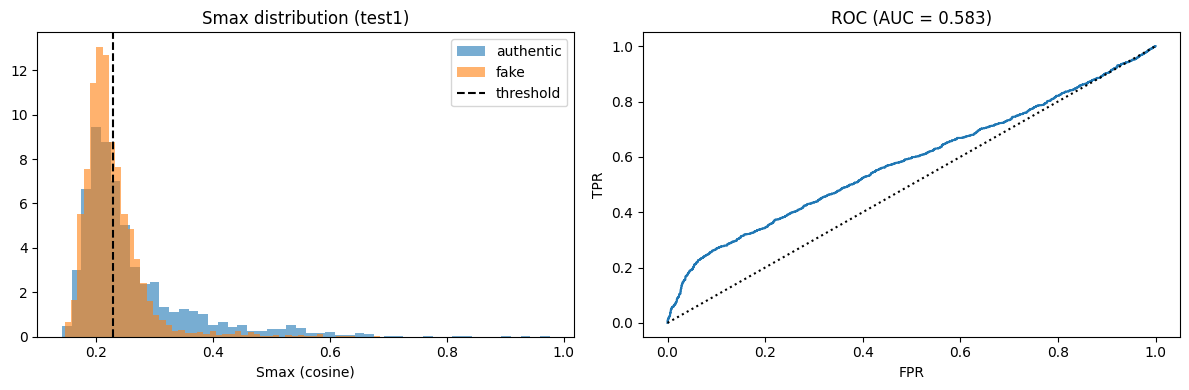

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

s_cal, y_cal, _ = valid(CAL_SPLIT)
fpr, tpr, thr = roc_curve(y_cal, s_cal)          # positive class = authentic (high Smax)
i = np.argmin(np.abs((1 - tpr) - fpr))
THRESH = float(thr[i])
print(f'Threshold from {CAL_SPLIT}: {THRESH:.4f}  (EER = {(fpr[i] + 1 - tpr[i]) / 2:.3f})')

s_te, y_te, m_te = valid(TEST_SPLIT)
pred = (s_te >= THRESH).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=[0, 1]).ravel()
FAR = fp / (fp + tn)   # fakes accepted as authentic
FRR = fn / (fn + tp)   # authentic rejected as fake
metrics = dict(n_scored=int(len(y_te)), coverage=float(m_te.mean()),
               accuracy=float((tp + tn) / len(y_te)), AUC=float(roc_auc_score(y_te, s_te)),
               FAR=float(FAR), FRR=float(FRR), HTER=float((FAR + FRR) / 2), threshold=THRESH)
for k, v in metrics.items():
    print(f'{k:>10}: {v:.4f}' if isinstance(v, float) else f'{k:>10}: {v}')
print('Confusion matrix [rows: true fake, authentic | cols: pred fake, authentic]:\n', [[tn, fp], [fn, tp]])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(s_te[y_te == 1], 50, alpha=.6, density=True, label='authentic')
ax[0].hist(s_te[y_te == 0], 50, alpha=.6, density=True, label='fake')
ax[0].axvline(THRESH, color='k', ls='--', label='threshold')
ax[0].set(title=f'Smax distribution ({TEST_SPLIT})', xlabel='Smax (cosine)'); ax[0].legend()
f2, t2, _ = roc_curve(y_te, s_te)
ax[1].plot(f2, t2); ax[1].plot([0, 1], [0, 1], 'k:')
ax[1].set(title=f'ROC (AUC = {metrics["AUC"]:.3f})', xlabel='FPR', ylabel='TPR')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'smax_roc.png'), dpi=150); plt.show()

## 7. Score-based likelihood ratio (logistic-regression calibration)
H1 (numerator): image is authentic · H2 (denominator): image is a face-swap. The paper used the LIR Python package; this is the equivalent logistic-regression calibration in scikit-learn.

Cllr on test1: 0.9682   (0 = perfect, 1 = uninformative)


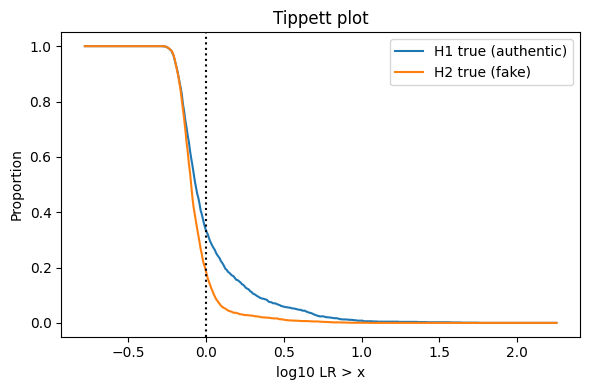

In [7]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(class_weight='balanced', C=1e6)   # balanced -> prior odds 1, so logit = ln(LR)
lr_model.fit(s_cal.reshape(-1, 1), y_cal)

def log10_LR(s):
    return lr_model.decision_function(np.asarray(s, float).reshape(-1, 1)) / np.log(10)

def cllr(llr10, y):
    ln = llr10 * np.log(10)
    return 0.5 * (np.mean(np.logaddexp(0, -ln[y == 1])) + np.mean(np.logaddexp(0, ln[y == 0]))) / np.log(2)

llr_te = log10_LR(s_te)
metrics['Cllr'] = float(cllr(llr_te, y_te))
print(f'Cllr on {TEST_SPLIT}: {metrics["Cllr"]:.4f}   (0 = perfect, 1 = uninformative)')

xs = np.linspace(llr_te.min() - .5, llr_te.max() + .5, 400)
plt.figure(figsize=(6, 4))
plt.plot(xs, [(llr_te[y_te == 1] > x).mean() for x in xs], label='H1 true (authentic)')
plt.plot(xs, [(llr_te[y_te == 0] > x).mean() for x in xs], label='H2 true (fake)')
plt.axvline(0, color='k', ls=':')
plt.xlabel('log10 LR > x'); plt.ylabel('Proportion'); plt.title('Tippett plot'); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'tippett.png'), dpi=150); plt.show()

## 8. Save per-image results (with human-review flag)

In [8]:
import json, pandas as pd

def verbal(l):
    a = abs(l)
    lvl = ('weak' if a < 1 else 'moderate' if a < 2 else 'moderately strong' if a < 3
           else 'strong' if a < 4 else 'very strong')
    return f'{lvl} support for ' + ('authentic' if l > 0 else 'fake')

p_all, y_all = np.array(data[TEST_SPLIT][0]), data[TEST_SPLIT][1]
s_all = scores[TEST_SPLIT]
rows = []
for p, y, s in zip(p_all, y_all, s_all):
    if np.isnan(s):
        rows.append(dict(path=p, true=int(y), Smax=None, decision='no face detected',
                         log10_LR=None, evidence=None, human_review=True))
    else:
        l = float(log10_LR([s])[0])
        rows.append(dict(path=p, true=int(y), Smax=float(s),
                         decision='authentic' if s >= THRESH else 'fake',
                         log10_LR=l, evidence=verbal(l), human_review=abs(l) < 1))
df = pd.DataFrame(rows)
df.to_csv(os.path.join(OUT, f'predictions_{TEST_SPLIT}.csv'), index=False)
json.dump(metrics, open(os.path.join(OUT, 'metrics.json'), 'w'), indent=2)
print(df['decision'].value_counts(), '\nFlagged for human review:', int(df['human_review'].sum()))
df.head()

decision
no face detected    2779
fake                2005
authentic           1462
Name: count, dtype: int64 
Flagged for human review: 6234


,path,true,Smax,decision,log10_LR,evidence,human_review
0,/content/drive/MyDrive/ML-dataset/P2datasetFul...,1,NaN,no face detected,NaN,None,True
1,/content/drive/MyDrive/ML-dataset/P2datasetFul...,1,NaN,no face detected,NaN,None,True
2,/content/drive/MyDrive/ML-dataset/P2datasetFul...,1,NaN,no face detected,NaN,None,True
3,/content/drive/MyDrive/ML-dataset/P2datasetFul...,1,NaN,no face detected,NaN,None,True
4,/content/drive/MyDrive/ML-dataset/P2datasetFul...,1,0.202312,fake,-0.128138,weak support for fake,True


## 9. Score a single new image

In [9]:
def evaluate_image(path):
    e = embed(path)
    if e is None:
        return {'path': path, 'result': 'no face detected - send to human review'}
    s = float(smax(e[None], np.array([True]))[0]); l = float(log10_LR([s])[0])
    return {'path': path, 'Smax': round(s, 4), 'decision': 'authentic' if s >= THRESH else 'fake',
            'log10_LR': round(l, 3), 'evidence': verbal(l), 'human_review': abs(l) < 1}

evaluate_image(data[TEST_SPLIT][0][0])

{'path': '/content/drive/MyDrive/ML-dataset/P2datasetFull/test1/1/0.039679_100291.jpg',
 'result': 'no face detected - send to human review'}